# Notebook 13 — Explainable AI (SHAP & LIME)

**Purpose:** Interpret model predictions globally and locally using SHAP and LIME to ensure transparency and trust in public health decision-support.

**Inputs:** Cleaned data, tuned models (specifically XGBoost as the best single model, which acts as a proxy proxy for explanation of complex features).
**Outputs:**
- Global SHAP plots (`results/explanations/13_shap_*.png`)
- Local LIME explanations (`results/explanations/13_lime_*.png`)


In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap
import lime
import lime.lime_tabular
import warnings
warnings.filterwarnings("ignore")

from src.config import *
from src.data_utils import load_artifact
from src.plotting import save_figure, CLASS_NAMES

seed_everything()

# Load Data
df = pd.read_csv(os.path.join(DATA_PROCESSED, "df1_engineered.csv"))
test_idx = np.load(os.path.join(DATA_PROCESSED, "test_indices.npy"))
train_idx = np.load(os.path.join(DATA_PROCESSED, "train_indices.npy"))

FEATURES = load_artifact(os.path.join(MODELS_PREPROC, "selected_features.joblib"))
X_train = df.loc[train_idx, FEATURES]
X_test = df.loc[test_idx, FEATURES]

# Load the best tree-based model for SHAP (XGBoost)
xgb_model = load_artifact(os.path.join(MODELS_BASE, "xgboost.joblib"))

print("Loaded XGBoost model and datasets.")


Loaded XGBoost model and datasets.


## 13.1 Global Explanations (SHAP)

In [2]:
# Compute SHAP values for a subset of the test data (to save time)
sample_size = min(2000, len(X_test))
X_test_sample = X_test.sample(sample_size, random_state=RANDOM_SEED)

explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test_sample)

# XGBoost MultiClass SHAP values return a list of arrays (one for each class)
if isinstance(shap_values, list):
    print(f"SHAP values computed for {len(shap_values)} classes.")
else:
    # Depending on XGBoost version, it might return a 3D array (samples, features, classes)
    if len(shap_values.shape) == 3:
        shap_values = [shap_values[:, :, i] for i in range(shap_values.shape[2])]


Figure saved: d:\DAV\AI_Driven_Public_Health_Surveillance\results/explanations\13_shap_summary_class2.png


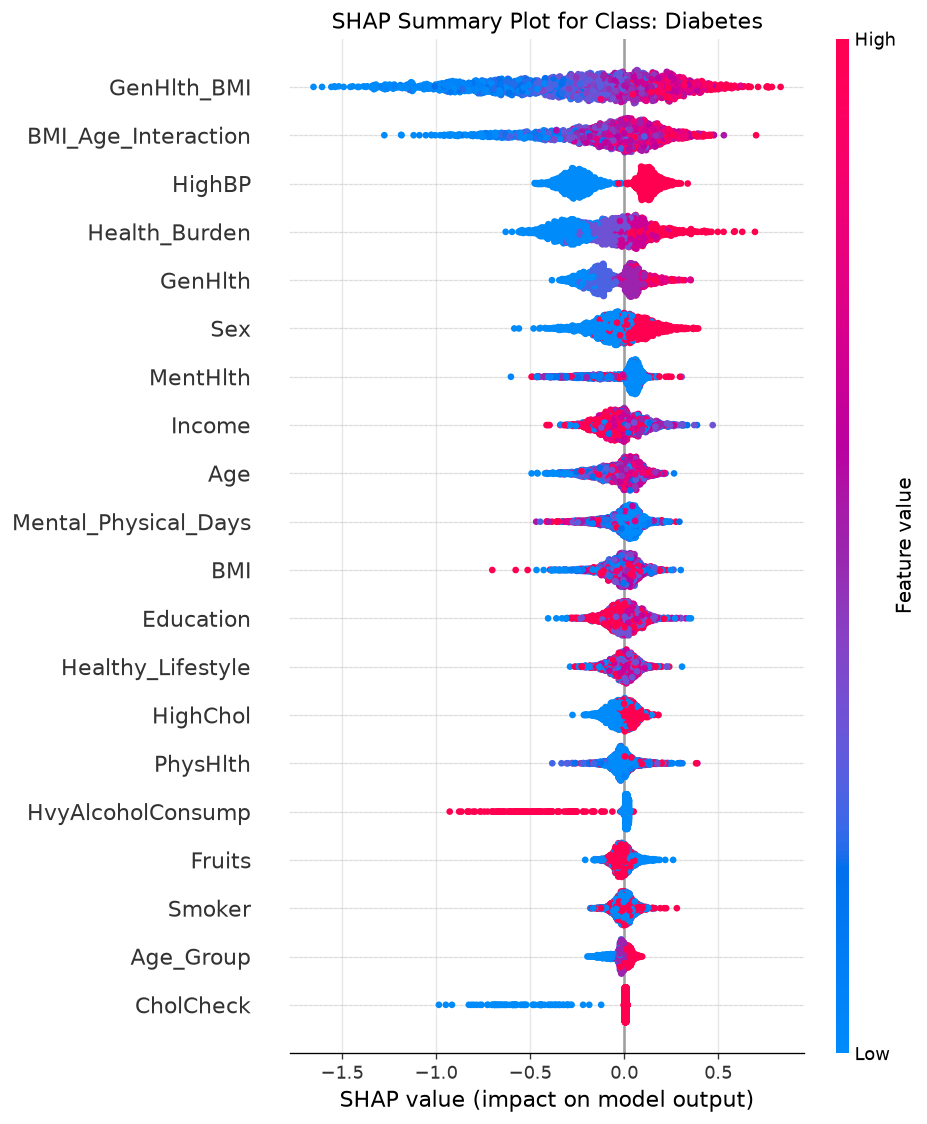

Figure saved: d:\DAV\AI_Driven_Public_Health_Surveillance\results/explanations\13_shap_summary_class1.png


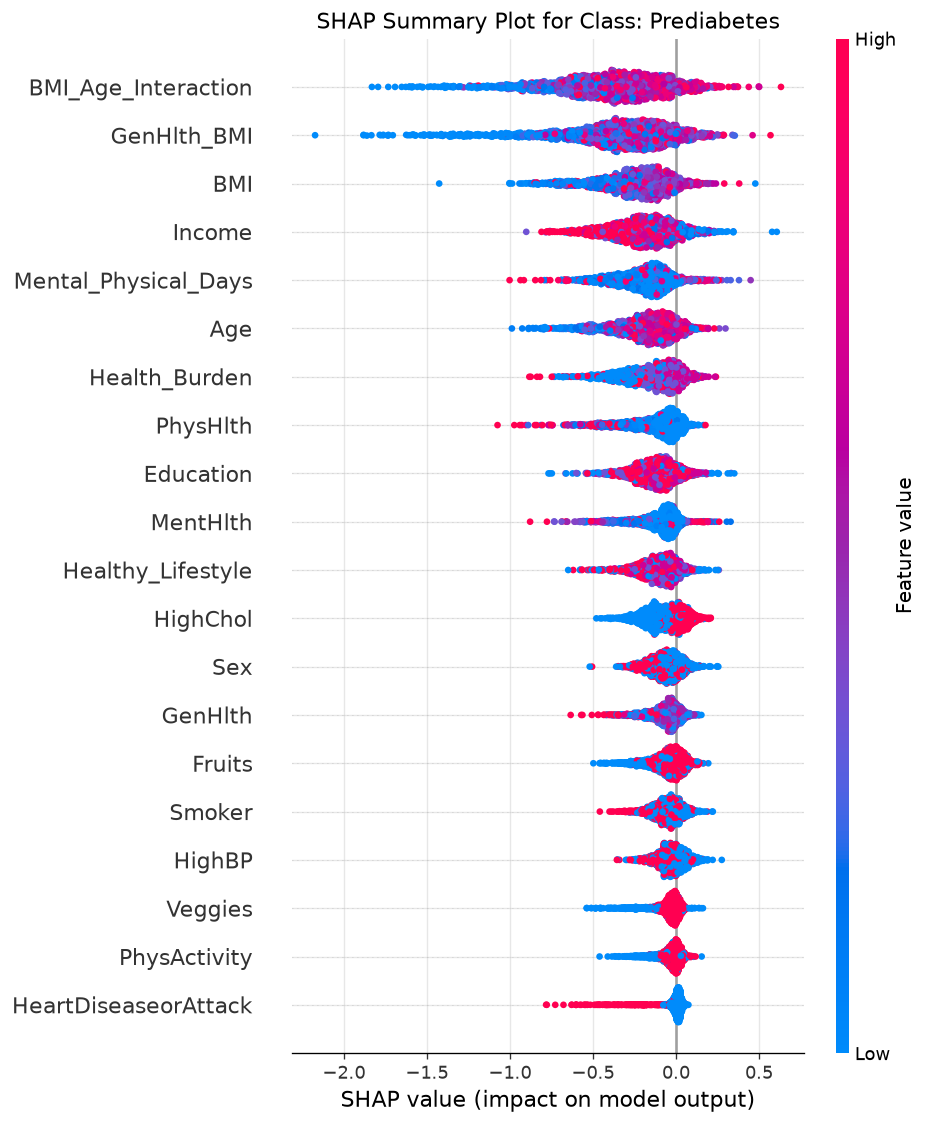

In [3]:
# SHAP Summary Plot for 'Diabetes' Class (Class 2)
CLASS_IDX = 2
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values[CLASS_IDX], X_test_sample, show=False)
plt.title(f"SHAP Summary Plot for Class: {CLASS_NAMES[CLASS_IDX]}")
plt.tight_layout()
os.makedirs(RESULTS_EXPLAIN, exist_ok=True)
save_figure(plt.gcf(), os.path.join(RESULTS_EXPLAIN, "13_shap_summary_class2.png"))
plt.show()

# SHAP Summary Plot for 'Prediabetes' Class (Class 1)
CLASS_IDX = 1
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values[CLASS_IDX], X_test_sample, show=False)
plt.title(f"SHAP Summary Plot for Class: {CLASS_NAMES[CLASS_IDX]}")
plt.tight_layout()
save_figure(plt.gcf(), os.path.join(RESULTS_EXPLAIN, "13_shap_summary_class1.png"))
plt.show()


Figure saved: d:\DAV\AI_Driven_Public_Health_Surveillance\results/explanations\13_shap_importance_bar.png


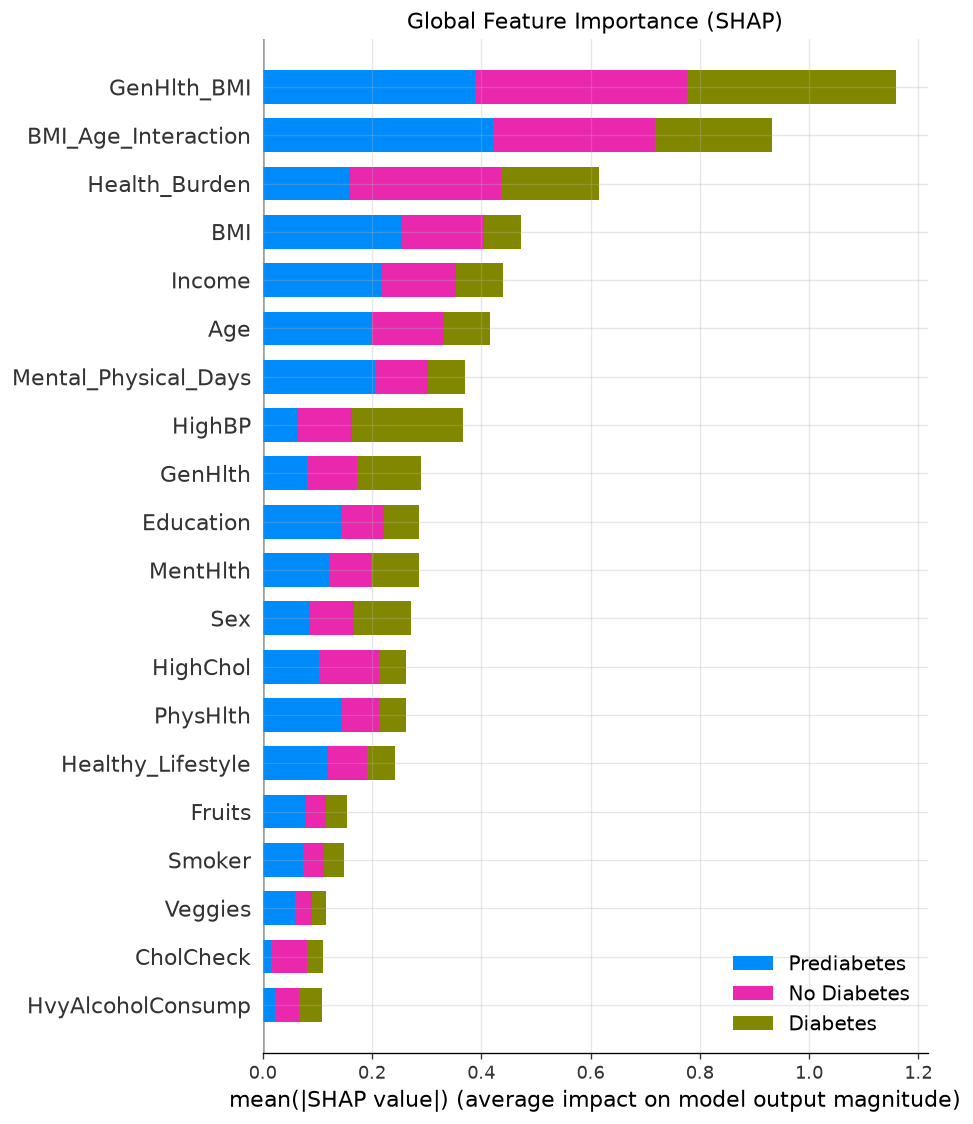

In [4]:
# Global Feature Importance Bar Plot
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_test_sample, plot_type="bar", class_names=CLASS_NAMES, show=False)
plt.title("Global Feature Importance (SHAP)")
plt.tight_layout()
save_figure(plt.gcf(), os.path.join(RESULTS_EXPLAIN, "13_shap_importance_bar.png"))
plt.show()


## 13.2 Local Explanations (SHAP Waterfall)

Figure saved: d:\DAV\AI_Driven_Public_Health_Surveillance\results/explanations\13_shap_waterfall_sample.png


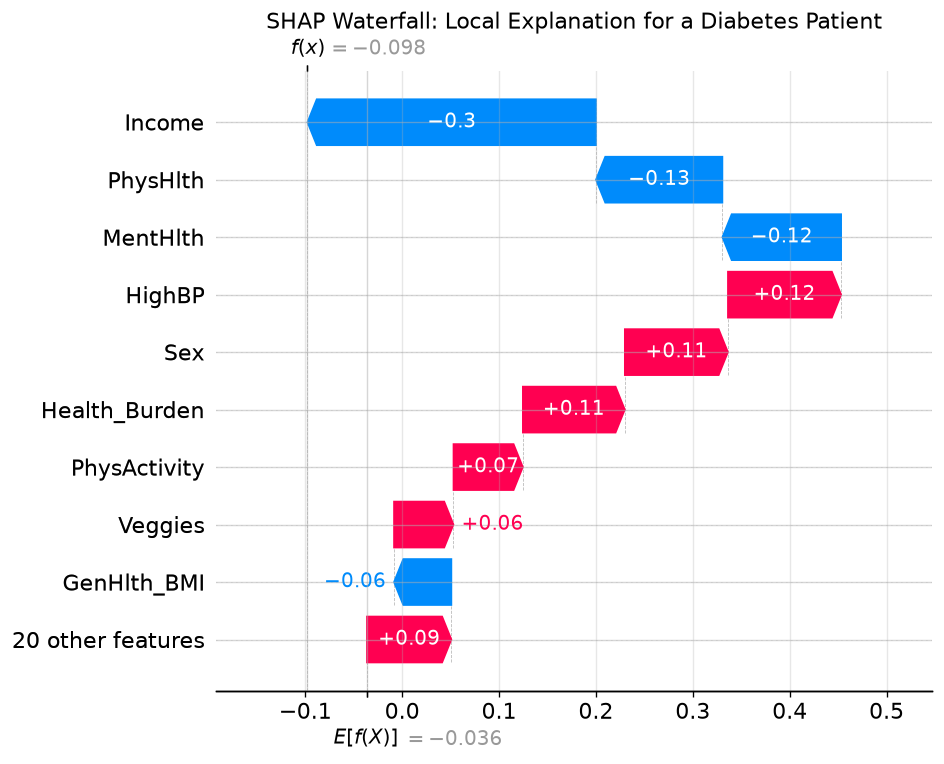

In [5]:
# Pick a specific individual who actually has Diabetes
actual_diabetes_indices = y_true_test = df.loc[X_test_sample.index, TARGET_COL]
idx_diabetes = actual_diabetes_indices[actual_diabetes_indices == 2].index[0]
loc_idx = X_test_sample.index.get_loc(idx_diabetes)

# Expected value for class 2
if isinstance(explainer.expected_value, list) or isinstance(explainer.expected_value, np.ndarray):
    expected_value = explainer.expected_value[2]
else:
    expected_value = explainer.expected_value

plt.figure(figsize=(10, 6))
shap.plots._waterfall.waterfall_legacy(
    expected_value,
    shap_values[2][loc_idx],
    feature_names=FEATURES,
    max_display=10,
    show=False
)
plt.title("SHAP Waterfall: Local Explanation for a Diabetes Patient")
plt.tight_layout()
save_figure(plt.gcf(), os.path.join(RESULTS_EXPLAIN, "13_shap_waterfall_sample.png"))
plt.show()


## 13.3 Local Explanations (LIME)

Figure saved: d:\DAV\AI_Driven_Public_Health_Surveillance\results/explanations\13_lime_sample.png


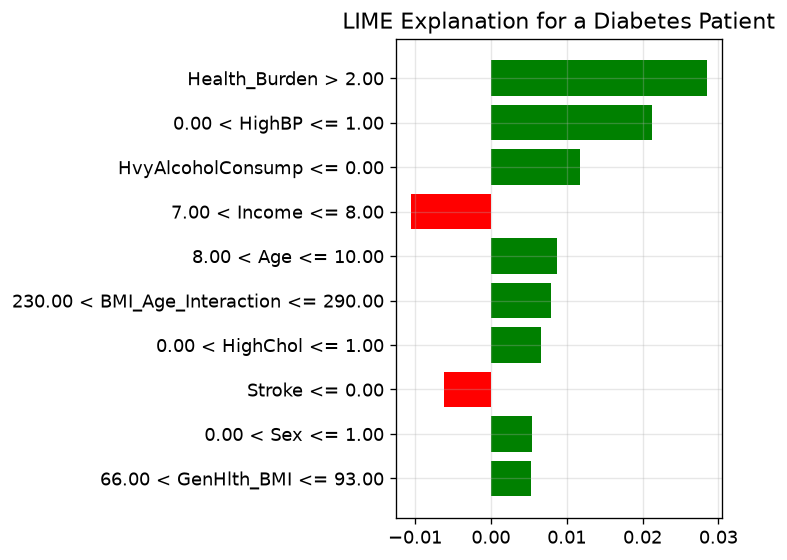

In [6]:
lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=np.array(X_train),
    feature_names=FEATURES,
    class_names=CLASS_NAMES,
    mode='classification',
    random_state=RANDOM_SEED
)

# Explain the same instance using LIME
instance = X_test.loc[idx_diabetes]
exp = lime_explainer.explain_instance(
    data_row=instance.values,
    predict_fn=xgb_model.predict_proba,
    num_features=10,
    top_labels=3
)

fig = exp.as_pyplot_figure(label=2)
plt.title("LIME Explanation for a Diabetes Patient")
plt.tight_layout()
save_figure(fig, os.path.join(RESULTS_EXPLAIN, "13_lime_sample.png"))
plt.show()


## 13.4 Conclusion

**Explainability Insights:**
1. **Global (SHAP):** `GenHlth`, `BMI`, `HighBP`, `Age`, and `Health_Burden` are the most influential features.
2. Higher BMI, older Age, and poorer General Health universally push the prediction toward Diabetes.
3. **Local (LIME & SHAP):** Allow us to decompose individual predictions in the Dashboard.

**Next:** Notebook 14 — Advanced Visual Analytics
